<a href="https://colab.research.google.com/github/NoDanCoder/AirBnB_clone/blob/master/Semana7/SistemasLineales.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import axes3d

In [4]:
A = np.array([[3,-1,-1],[-1.,3.,1.],[2,1,4]])
b = np.array([1.,3.,7.])
A

array([[ 3., -1., -1.],
       [-1.,  3.,  1.],
       [ 2.,  1.,  4.]])

In [5]:
xsol = np.linalg.solve(A,b)
xsol

array([1., 1., 1.])

In [6]:

def GetZ(A,b,x,y,i):
    return (b[i] - A[i,0]*x - A[i,1]*y)/A[i,2]

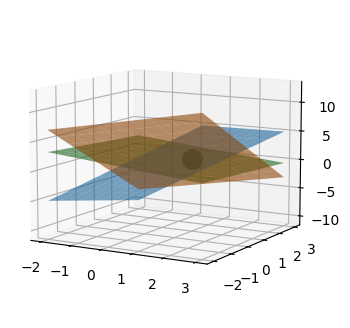

In [7]:

x = np.linspace(-2,3,10)
y = np.linspace(-2,3,10)
X,Y = np.meshgrid(x,y)

fig = plt.figure(figsize=(4,4))
ax = fig.add_subplot(111, projection='3d', elev=10, azim = -60)

for i in range(3):
    ax.plot_surface(X,Y,GetZ(A,b,X,Y,i),alpha=0.6)

ax.scatter(xsol[0],xsol[1],xsol[2],color='k',s=200)



In [8]:
import plotly.graph_objects as go

surfaces = []
for i in range(3):
    Z = GetZ(A, b, X, Y, i)
    surfaces.append(
        go.Surface(
            x=X, y=Y, z=Z,
            opacity=0.4,
            colorscale='Viridis',
            showscale=False,
            name=f"Plano {i+1}"
        )
    )

fig = go.Figure(data=surfaces)

point = go.Scatter3d(
    x=[xsol[0]], y=[xsol[1]], z=[xsol[2]],
    mode='markers+text',
    text=[f"sol: ({xsol[0]:.3f}, {xsol[1]:.3f}, {xsol[2]:.3f})"],
    textposition="top center",
    marker=dict(size=3),
    name="Solución"
)

fig.add_trace(point)
fig.show()



In [9]:
def jacobi(A,b,x0,itmax=100,tol=1e-13):

  x = x0.copy()

  for it in range(itmax):

    xnew = np.copy(x)

    # itero sobre las filas
    for i in range(A.shape[0]):

      Suma = 0.
      for j in range(A.shape[1]):
        if i != j:
          Suma += A[i,j]*x[j]

      xnew[i] = (b[i] - Suma)/A[i,i]


      x[i] = xnew[i]

    residuo = np.linalg.norm( np.dot(A,x) - b )
    #print(residuo)

    if residuo < tol:
      print('Converge el metodo')
      print(it)
      break

  return x



In [10]:
x0 = np.array([3.,1.,2.])
jacobi(A,b,x0)

Converge el metodo
22


array([1., 1., 1.])

In [24]:
A = np.array([[2., -1., 0.], [-1., 2., -1.], [0., -1., 2.]])
b = np.array([0., 0., 10.])

sol = jacobi(A, b, np.array([0., 0., 10.]))

Converge el metodo
1


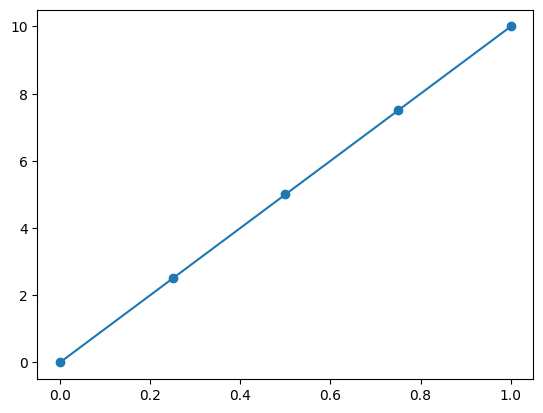

In [37]:
plt.scatter(np.linspace(0., 1., 5), np.concatenate([[0.], sol, [10.]]))
plt.plot(np.linspace(0., 1., 5), np.concatenate([[0.], sol, [10.]]))
plt.show()